In [45]:
import io
import pandas as pd
import scanpy as sc
import gcsfs
import os
import matplotlib.pyplot as plt

In [17]:
fs = gcsfs.GCSFileSystem(token='anon')

In [18]:
# GCS bucket path for Virtual Cell Challenge 2025 datasets
vcc_base_path = "gs://arc-institute-virtual-cell-atlas/virtual-cell-challenge/2025/"

In [19]:
# load data
train_adata_path = vcc_base_path + "train/adata_Training.h5ad"
val_adata_path = vcc_base_path + "validation/adata_Validation.h5ad"

print(f"Training data path: {train_adata_path}")  # 150 perturbations
print(f"Validation data path: {val_adata_path}")  # 50 perturbations

Training data path: gs://arc-institute-virtual-cell-atlas/virtual-cell-challenge/2025/train/adata_Training.h5ad
Validation data path: gs://arc-institute-virtual-cell-atlas/virtual-cell-challenge/2025/validation/adata_Validation.h5ad


In [21]:
print(fs.info(train_adata_path)["size"] / 1000000000)  # data size in GB --> took forever to stream into memory
print(fs.info(val_adata_path)["size"] / 1000000000)

15.482497461
6.928967541


In [ ]:
# read in the data --- takes forever so try new approach
# with fs.open(train_adata_path) as f:
#     adata = sc.read_h5ad(f)
# adata

# with fs.open(val_adata_path) as f:
#     adata_val = sc.read_h5ad(f)
# adata_val

In [26]:
local_train = "../../data/adata_Training.h5ad"  # make local file
if not os.path.exists(local_train):
    fs.get(train_adata_path, local_train)  # get function downloads the file from google cloud to local path

adata = sc.read_h5ad(local_train)  # read the local file into the adata variable
adata

AnnData object with n_obs × n_vars = 221273 × 18080
    obs: 'target_gene', 'guide_id', 'batch'
    var: 'gene_id'

In [28]:
local_val = "../../data/adata_Validation.h5ad"  # make local file
if not os.path.exists(local_val):
    fs.get(val_adata_path, local_val)  # get function downloads the file from google cloud to local path

adata_val = sc.read_h5ad(local_val)  # read the local file into the adata variable
adata_val

AnnData object with n_obs × n_vars = 98927 × 18080
    obs: 'target_gene', 'guide_id', 'batch'
    var: 'n_cells_by_counts', 'mean_counts', 'log1p_mean_counts', 'pct_dropout_by_counts', 'total_counts', 'log1p_total_counts', 'mt', 'ribo', 'n_cells'

In [11]:
counts_path = vcc_base_path + "train/pert_counts_Training.csv"
counts = pd.read_csv(fs.open(counts_path))
counts.head()

Could not determine bucket type for bucket name arc-institute-virtual-cell-atlas: Your default credentials were not found. To set up Application Default Credentials, see https://cloud.google.com/docs/authentication/external/set-up-adc for more information., falling back to GCSFileSystem
Could not determine bucket type for bucket name arc-institute-virtual-cell-atlas: Your default credentials were not found. To set up Application Default Credentials, see https://cloud.google.com/docs/authentication/external/set-up-adc for more information., falling back to GCSFileSystem
Could not determine bucket type for bucket name arc-institute-virtual-cell-atlas: Your default credentials were not found. To set up Application Default Credentials, see https://cloud.google.com/docs/authentication/external/set-up-adc for more information., falling back to GCSFileSystem
Could not determine bucket type for bucket name arc-institute-virtual-cell-atlas: Your default credentials were not found. To set up App

,target_gene,n_cells,median_umi_per_cell
0,TMSB4X,4760,53652.0
1,PRCP,4331,54594.0
2,TADA1,4035,52376.0
3,HIRA,3407,54068.0
4,IGF2R,3109,55754.0


In [29]:
adata.X[:2].toarray()  # will show the expression profile for the first two cells in the training dataset. The expression profile is a matrix where rows represent cells and columns represent genes

array([[0., 0., 1., ..., 0., 0., 1.],
       [0., 1., 0., ..., 0., 0., 1.]], shape=(2, 18080), dtype=float32)

In [30]:
adata.obs  # shows a table with rows representing cells, and which gene was perturbed in that cell aka the perturbation 

,target_gene,guide_id,batch
AAACAAGCAACCTTGTACTTTAGG-Flex_1_01,CHMP3,CHMP3_P1P2_A|CHMP3_P1P2_B,Flex_1_01
AAACAAGCATTGCCGCACTTTAGG-Flex_1_01,AKT2,AKT2_P1P2_A|AKT2_P1P2_B,Flex_1_01
AAACCAATCAATGTTCACTTTAGG-Flex_1_01,SHPRH,SHPRH_P1P2_A|SHPRH_P1P2_B,Flex_1_01
AAACCAATCCCTCGCTACTTTAGG-Flex_1_01,TMSB4X,TMSB4X_P1_A|TMSB4X_P1_B,Flex_1_01
AAACCAATCTAAATCCACTTTAGG-Flex_1_01,KLF10,KLF10_P2_A|KLF10_P2_B,Flex_1_01
...,...,...,...
TTTGGACGTGGTGCAGATTCGGTT-Flex_3_16,non-targeting,non-targeting_00035|non-targeting_03439,Flex_3_16
TTTGTGAGTAGTAGCAATTCGGTT-Flex_3_16,KDM1A,KDM1A_P1P2_A|KDM1A_P1P2_B,Flex_3_16
TTTGTGAGTCCATCCTATTCGGTT-Flex_3_16,non-targeting,non-targeting_00020|non-targeting_01323,Flex_3_16
TTTGTGAGTCCTGACAATTCGGTT-Flex_3_16,BIRC2,BIRC2_P1P2_A|BIRC2_P1P2_B,Flex_3_16


In [35]:
# what we wanted for input was expression and perturbation
#expression:
print(adata.X[:2].toarray())  # perturbed expression profile for the first two cells --> this is the OUTPUT
#perturbation:
print(adata.obs.target_gene[:2])  # shows the perturbation information for the first two cells

[[0. 0. 1. ... 0. 0. 1.]
 [0. 1. 0. ... 0. 0. 1.]]
AAACAAGCAACCTTGTACTTTAGG-Flex_1_01    CHMP3
AAACAAGCATTGCCGCACTTTAGG-Flex_1_01     AKT2
Name: target_gene, dtype: category
Categories (151, object): ['ACAT2', 'ACVR1B', 'AKT2', 'ANTXR1', ..., 'ZNF562', 'ZNF593', 'ZNF714', 'non-targeting']


In [38]:
# # we need the unperturbed expression profile for the first two cells --> this is the INPUT
# #unperturbed expression is non-targeting
print(adata.X[-3].toarray())
# #perturbation will say non-targeting instead of a gene name
print(adata.obs.target_gene[-3])  

[[0. 3. 0. ... 0. 1. 0.]]
non-targeting


C:\Users\ryryl\AppData\Local\Temp\ipykernel_12796\3902473539.py:5: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  print(adata.obs.target_gene[-3])


In [39]:
adata.var  # information about the genes in the data -- only have gene symbols and ensembl ids

,gene_id
SAMD11,ENSG00000187634
NOC2L,ENSG00000188976
KLHL17,ENSG00000187961
PLEKHN1,ENSG00000187583
PERM1,ENSG00000187642
...,...
MT-ND4L,ENSG00000212907
MT-ND4,ENSG00000198886
MT-ND5,ENSG00000198786
MT-ND6,ENSG00000198695


In [ ]:
# first_cell = adata.X[0].toarray().flatten()  # get the expression profile for the first cell
# this is the number of UMIs; diff cells get sequenced to diff depths due to technical variation -- need to correct for this difference in counts for the genes in the cells that get sequenced deeper

# # normlaize for counts per million
# first_cell / first_cell.sum() * 1e4  # also a scanpy function

sc.pp.normalize_total(adata, target_sum=1e4)  # normalize the counts per cell to a total of 10,000 counts per cell

In [ ]:
# show the two methods of normalization
adata_copy = adata.copy()

In [ ]:
first_cell = adata_copy.X[0].toarray().flatten()
first_cell / first_cell.sum() * 1e4
print(False in (first_cell == adata.X[0].toarray().flatten()))  # check if the two methods of normalization are the same


False


In [ ]:
## data is still really skewed with just normalization 
sc.pp.log1p(adata)  # log transform the data which is just ln(data + 1) to avoid taking the log of 0

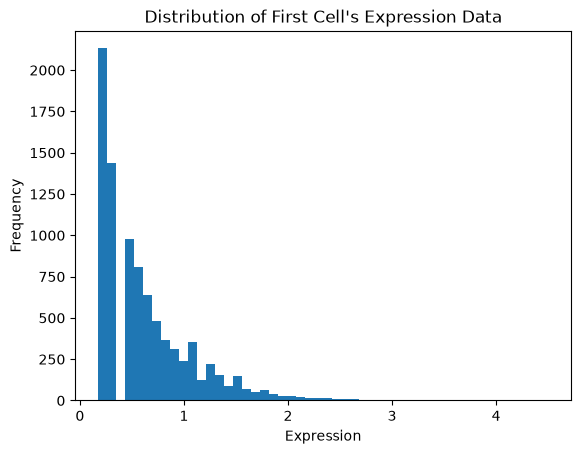

In [ ]:
# plot the distribution of the first cell's expression profile after normalization and log transformation
# variance is stabilizaed across genes 
first_cell = adata.X[0].toarray().flatten()
plt.hist(first_cell[first_cell > 0], bins=50)
plt.xlabel('Expression')
plt.ylabel('Frequency')
plt.title('Distribution of First Cell\'s Expression Data')
plt.show()


In [2]:
class Cell:
    def __init__(self, expression):
        self.expression = expression  # gene 1 with some amount of mRNA in format of dictionary

    def perturb(self, condition):
        if condition == 'hypoxia':
            # simulate hypoxia by increasing HIF1A expression and decreasing EGLN2 expression
            self.expression['HIF1A'] *= 2  # double HIF1A expression
            self.expression['EGLN2'] *= 0.5  # half EGLN2 expression
        elif condition == 'hyperoxia':
            # opposite effect: decrease HIF1A and increase EGLN2
            self.expression['HIF1A'] *= 0.5  # half HIF1A expression
            self.expression['EGLN2'] *= 2  # double EGLN2 expression
        
        return self

    def __str__(self):
        return self.expression.__str__()


In [ ]:
cell = Cell({'HIF1A':1, 'EGLN2': 1})  # general idea: 1. provide expression profile
print(cell)

perturbed_cell = cell.perturb('hypoxia')  # 2. perturb cell under some condition
print(perturbed_cell)  # 3. see the effect of perturbation on expression profile

perturbed_cell = cell.perturb('hyperoxia')
print(perturbed_cell)

{'HIF1A': 1, 'EGLN2': 1}
{'HIF1A': 2, 'EGLN2': 0.5}
{'HIF1A': 1.0, 'EGLN2': 1.0}
